## 09. Climate-ESG Risk Intelligence: Feature Engineering and Feed-Forward Neural Network (PyTorch) 

**Project Title**

**AI-Powered Climate & ESG Risk Intelligence Platform for Multi-Sector Decision Support in Germany**


| **Project Information** |                                                                                                                                                          |
| ----------------------- | -------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **Project Title**       | **AI-Powered Climate & ESG Risk Intelligence Platform for Multi-Sector Decision Support in Germany**                                                     |
| **Case Organization**   | **KlimaIQ Analytics GmbH** *(Fictional Industry Case Study)*                                                                                             |
| **Author**              | **Purity Mbaabu**                                                                                                                                        |
| **Role (Case Study)**   | Full-Stack AI Engineer, KlimaIQ Analytics GmbH                                                                                                       |
| **Program**             | AI Engineering – Digethic Business School, Germany                                                                                                  |
| **Project Date**        | July 2026                                                                                                                                          |
| **Study Area**          | Germany (400 Districts / Project400 Framework)                                                                                                       |
| **Study Period (Data)** | 1990–2025                                                                                                                                           
| **Dataset**             | Integrated Climate-ESG Master Dataset (14,400 observations)                                                                                                     |
| **Model**               | Feed-Forward Neural Network (PyTorch)                                                                                                                |
| **Objective**           | Design, train, evaluate, and explain a prototype Feed-Forward Neural Network (FFNN) for district-level Climate & ESG Risk Index prediction. |
| **Solution Type**       | Prototype AI-Powered Climate & ESG Decision-Support System |



### Overview

This notebook develops the machine learning pipeline for the Climate-ESG Risk Intelligence Germany project. Using the integrated master dataset produced in Notebook 08, it performs data validation, feature engineering, target variable construction, neural network development, model evaluation, and explainability.

The objective is to develop a Feed-Forward Neural Network (FFNN) capable of learning relationships between regional climate hazards and socioeconomic indicators to estimate district-level climate risk across Germany's 400 districts.

**Data Inputs**

This notebook uses the integrated master dataset created during the harmonization phase:

- Climate-ESG master dataset (1990–2025)
- 400 German districts (Project400 administrative framework)
- 36-year time series (1990–2025)

The Climate-ESG master dataset (1990–2025) is constructed from five feature datasets as below:

##### Three climate hazard indicators:
- Heatwave Days
- Flood Proxy (Rx5day)
- Meteorological Drought Magnitude

##### Two socioeconomic indicators:
- GDP per capita
- Unemployment rate

**Dataset characteristics:**

- Districts: 400
- Years: 1990–2025
- Total observations: 14,400

**Objective**

| **Objective** | Develop, train, evaluate, and explain a prototype Feed-Forward Neural Network (FFNN) for district-level Climate & ESG Risk Index prediction. |

**Specifically, this notebook:**

1. validates the integrated master dataset;
2. engineers machine learning features;
3. constructs the Climate Risk Index target variable;
4. partitions the data into training, validation, and testing sets;
5. scales predictor variables;
6. develops and trains a PyTorch Feed-Forward Neural Network;
7. evaluates predictive performance using regression metrics;
8. interprets model behaviour using SHAP explainability; and
9. exports the trained model and preprocessing objects for deployment.

**Why this step?**

Notebook 08 completed the data engineering phase by integrating harmonized climate and socioeconomic datasets into a unified district-level master dataset.

This notebook transitions from data engineering to machine learning, transforming the harmonized data into predictive intelligence. The resulting FFNN provides a prototype AI model capable of learning nonlinear relationships between climate hazards and socioeconomic conditions that contribute to regional climate risk.

**Workflow**

1. Load the Climate-ESG master dataset.
2. Validate data quality and completeness.
3. Perform feature engineering.
4. Construct the Climate Risk Index target variable.
5. Split data into training, validation, and testing datasets.
6. Standardize predictor variables.
7. Develop the Feed-Forward Neural Network (PyTorch).
8. Train the neural network.
9. Evaluate model performance.
10. Interpret predictions using SHAP.
11. Export the trained model and preprocessing pipeline.

**Outputs**

- Validated Climate-ESG master dataset
- Engineered feature matrix
- Climate Risk Index target variable
- Trained Feed-Forward Neural Network
- Feature scaler
- SHAP explainability outputs
- Saved model ready for deployment

**Next Phase**

The trained neural network produced in this notebook will support the deployment stage of the project, where the model will be integrated into a Flask REST API and connected to a lightweight frontend for interactive district-level climate risk assessment.

### Import Required Libraries

In [2]:
# ============================================================
# Import Libraries
# ============================================================

# General
from pathlib import Path
import joblib
import warnings

# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

# Deep Learning
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Explainability
import shap

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Libraries imported successfully.")

print("=" * 60)
print("Environment")
print("=" * 60)
print(f"Pandas : {pd.__version__}")
print(f"NumPy  : {np.__version__}")
print(f"PyTorch: {torch.__version__}")
print("=" * 60)

Libraries imported successfully.
Environment
Pandas : 2.3.3
NumPy  : 2.3.4
PyTorch: 2.10.0+cpu


### Define Project Configuration

In [3]:
# ============================================================
# Project directories
# ============================================================

PROJECT_ROOT = Path.cwd().parent

MASTER_DATA = PROJECT_ROOT / "data" / "processed" / "master" / "master_dataset_1990_2025.csv"

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 60)
print("Project Paths")
print("=" * 60)
print(f"Project Root : {PROJECT_ROOT}")
print(f"Master Data  : {MASTER_DATA}")
print(f"Model Folder : {MODEL_DIR}")
print(f"Figures      : {FIGURE_DIR}")
print("=" * 60)

assert MASTER_DATA.exists(), "Master dataset not found."
print("✓ Master dataset located successfully.")
print("✓ Master dataset located successfully.")

Project Paths
Project Root : d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany
Master Data  : d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\data\processed\master\master_dataset_1990_2025.csv
Model Folder : d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\models
Figures      : d:\Purity\GitHub-Repository\climate-esg-risk-intelligence-germany\reports\figures
✓ Master dataset located successfully.
✓ Master dataset located successfully.


### Load Master Dataset

In [4]:
# ============================================================
# Step 2: Load Master Dataset
# ============================================================

# Load integrated master dataset
df = pd.read_csv(MASTER_DATA)

# Basic dataset information
n_rows, n_cols = df.shape
n_districts = df["district_code"].nunique()
n_years = df["year"].nunique()
min_year = df["year"].min()
max_year = df["year"].max()
expected_rows = 400 * 36

print("=" * 60)
print("Master Dataset Loaded")
print("=" * 60)
print(f"Rows          : {n_rows:,}")
print(f"Columns       : {n_cols}")
print(f"Districts     : {n_districts}")
print(f"Years         : {min_year}–{max_year} ({n_years} years)")
print(f"Expected rows : {expected_rows:,}")
print(f"Memory usage  : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print("=" * 60)

# Validation checks
assert n_rows == expected_rows, "Unexpected number of rows."
assert n_districts == 400, "Unexpected number of districts."
assert n_years == 36, "Unexpected number of years."

print("✓ Master dataset loaded successfully.")
print("✓ Dataset dimensions match expected Project400 × 1990–2025 panel structure.")

# Display first records
df.head()

Master Dataset Loaded
Rows          : 14,400
Columns       : 8
Districts     : 400
Years         : 1990–2025 (36 years)
Expected rows : 14,400
Memory usage  : 2.34 MB
✓ Master dataset loaded successfully.
✓ Dataset dimensions match expected Project400 × 1990–2025 panel structure.


,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
0,DE111,"Stuttgart, Stadtkreis",1990,0.0,69.070652,0.239709,49.1,8.16
1,DE111,"Stuttgart, Stadtkreis",1991,0.0,71.949109,8.796172,49.1,8.16
2,DE111,"Stuttgart, Stadtkreis",1992,0.0,65.218925,1.244216,49.1,8.16
3,DE111,"Stuttgart, Stadtkreis",1993,0.0,84.942949,2.221193,49.1,8.16
4,DE111,"Stuttgart, Stadtkreis",1994,0.0,66.135985,0.000000,49.1,8.16


In [6]:
print(df[["gdp_per_capita", "unemployment_rate"]].isna().sum())

gdp_per_capita       3996
unemployment_rate    3996
dtype: int64


In [7]:
# Districts with missing GDP values

missing_districts = (
    df[df["gdp_per_capita"].isna()]
    .groupby(["district_code", "district_name"])
    .size()
    .reset_index(name="missing_records")
)

print(f"Districts affected: {len(missing_districts)}")
display(missing_districts.head(20))

Districts affected: 111


,district_code,district_name,missing_records
0,DE118,"Heilbronn, Landkreis",36
1,DE123,"Karlsruhe, Landkreis",36
2,DE142,"Tübingen, Landkreis",36
3,DE211,"Ingolstadt, Kreisfreie Stadt",36
4,DE212,"München, Kreisfreie Stadt",36
5,DE213,"Rosenheim, Kreisfreie Stadt",36
6,DE21H,"München, Landkreis",36
7,DE21K,"Rosenheim, Landkreis",36
8,DE221,"Landshut, Kreisfreie Stadt",36
9,DE222,"Passau, Kreisfreie Stadt",36


In [8]:
print(df[df["gdp_per_capita"].isna()].year.unique())

[1990 1991 1992 1993 1994 1995 1996 1997 1998 1999 2000 2001 2002 2003
 2004 2005 2006 2007 2008 2009 2010 2011 2012 2013 2014 2015 2016 2017
 2018 2019 2020 2021 2022 2023 2024 2025]


### Dataset Validation & Quality Checks

In [9]:
# ============================================================
# Step 3: Dataset Validation & Quality Checks
# Dataset structure and data types
# ============================================================

print("=" * 60)
print("Dataset Structure & Data Types")
print("=" * 60)

# Basic structure
print(f"Dataset shape : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Memory usage  : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

print("\nColumn names:")
for col in df.columns:
    print(f" - {col}")

print("\nData types:")
print(df.dtypes)

# Expected schema
expected_columns = [
    "district_code",
    "district_name",
    "year",
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate",
]

missing_columns = [col for col in expected_columns if col not in df.columns]
extra_columns = [col for col in df.columns if col not in expected_columns]

print("\nSchema validation:")
print(f"Expected columns : {len(expected_columns)}")
print(f"Observed columns : {df.shape[1]}")
print(f"Missing columns  : {missing_columns if missing_columns else 'None'}")
print(f"Extra columns    : {extra_columns if extra_columns else 'None'}")

# Data type groups
identifier_cols = ["district_code", "district_name"]
time_cols = ["year"]
numeric_cols = [
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate",
]

print("\nColumn groups:")
print(f"Identifier columns : {identifier_cols}")
print(f"Time column        : {time_cols}")
print(f"Numeric features   : {numeric_cols}")

# Assertions
assert missing_columns == [], "Missing expected columns."
assert df.shape[1] == len(expected_columns), "Unexpected number of columns."
assert pd.api.types.is_numeric_dtype(df["year"]), "Year column must be numeric."

for col in numeric_cols:
    assert pd.api.types.is_numeric_dtype(df[col]), f"{col} must be numeric."

print("\n✓ Dataset schema matches expected structure.")
print("✓ Numeric modelling variables have valid numeric data types.")
print("=" * 60)



Dataset Structure & Data Types
Dataset shape : 14,400 rows × 8 columns
Memory usage  : 2.36 MB

Column names:
 - district_code
 - district_name
 - year
 - heatwave
 - flood
 - drought
 - gdp_per_capita
 - unemployment_rate

Data types:
district_code         object
district_name         object
year                   int64
heatwave             float64
flood                float64
drought              float64
gdp_per_capita       float64
unemployment_rate    float64
dtype: object

Schema validation:
Expected columns : 8
Observed columns : 8
Missing columns  : None
Extra columns    : None

Column groups:
Identifier columns : ['district_code', 'district_name']
Time column        : ['year']
Numeric features   : ['heatwave', 'flood', 'drought', 'gdp_per_capita', 'unemployment_rate']

✓ Dataset schema matches expected structure.
✓ Numeric modelling variables have valid numeric data types.


In [10]:
# ============================================================
# Step 3a: Dataset Validation & Quality Checks
# Completeness, duplicates, and panel integrity
# ============================================================

expected_districts = 400
expected_years = list(range(1990, 2026))
expected_rows = expected_districts * len(expected_years)

# ------------------------------------------------------------
# Missing values summary
# ------------------------------------------------------------

missing_summary = (
    pd.DataFrame({
        "column": df.columns,
        "missing_count": df.isna().sum().values,
        "missing_pct": (df.isna().mean().values * 100).round(2),
        "non_missing_count": df.notna().sum().values,
    })
    .sort_values("missing_count", ascending=False)
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Duplicate and panel checks
# ------------------------------------------------------------

duplicate_rows = df.duplicated().sum()
duplicate_district_year = df.duplicated(subset=["district_code", "year"]).sum()

observed_districts = df["district_code"].nunique()
observed_years = sorted(df["year"].unique().tolist())
observed_rows = len(df)

missing_years = sorted(set(expected_years) - set(observed_years))
extra_years = sorted(set(observed_years) - set(expected_years))

# Expected full district-year grid
expected_panel = pd.MultiIndex.from_product(
    [df["district_code"].unique(), expected_years],
    names=["district_code", "year"],
).to_frame(index=False)

actual_panel = df[["district_code", "year"]].drop_duplicates()

missing_panel_records = expected_panel.merge(
    actual_panel,
    on=["district_code", "year"],
    how="left",
    indicator=True,
).query("_merge == 'left_only'")

# ------------------------------------------------------------
# Print validation report
# ------------------------------------------------------------

print("=" * 60)
print("Dataset Completeness & Panel Integrity")
print("=" * 60)

print(f"Expected rows             : {expected_rows:,}")
print(f"Observed rows             : {observed_rows:,}")
print(f"Expected districts        : {expected_districts}")
print(f"Observed districts        : {observed_districts}")
print(f"Expected years            : {expected_years[0]}–{expected_years[-1]} ({len(expected_years)} years)")
print(f"Observed years            : {observed_years[0]}–{observed_years[-1]} ({len(observed_years)} years)")
print(f"Duplicate rows            : {duplicate_rows}")
print(f"Duplicate district-years  : {duplicate_district_year}")
print(f"Missing panel records     : {len(missing_panel_records):,}")
print("=" * 60)

print("\nMissing years:", missing_years if missing_years else "None")
print("Extra years  :", extra_years if extra_years else "None")

print("\nMissing values summary:")
display(missing_summary)

# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert observed_rows == expected_rows, "Observed row count does not match expected panel size."
assert observed_districts == expected_districts, "Unexpected number of districts."
assert observed_years == expected_years, "Observed years do not match expected 1990–2025 range."
assert duplicate_rows == 0, "Duplicate rows found."
assert duplicate_district_year == 0, "Duplicate district-year records found."
assert len(missing_panel_records) == 0, "Missing district-year panel records found."

print("✓ Dataset row count matches expected Project400 × 1990–2025 structure.")
print("✓ No duplicate records detected.")
print("✓ No missing district-year panel records detected.")
print("✓ Dataset completeness and panel integrity checks passed.")

Dataset Completeness & Panel Integrity
Expected rows             : 14,400
Observed rows             : 14,400
Expected districts        : 400
Observed districts        : 400
Expected years            : 1990–2025 (36 years)
Observed years            : 1990–2025 (36 years)
Duplicate rows            : 0
Duplicate district-years  : 0
Missing panel records     : 0

Missing years: None
Extra years  : None

Missing values summary:


,column,missing_count,missing_pct,non_missing_count
0,gdp_per_capita,3996,27.75,10404
1,unemployment_rate,3996,27.75,10404
2,district_code,0,0.00,14400
3,district_name,0,0.00,14400
4,heatwave,0,0.00,14400
5,year,0,0.00,14400
6,drought,0,0.00,14400
7,flood,0,0.00,14400


✓ Dataset row count matches expected Project400 × 1990–2025 structure.
✓ No duplicate records detected.
✓ No missing district-year panel records detected.
✓ Dataset completeness and panel integrity checks passed.


In [11]:
print()

print("Note")
print("-" * 60)
print(
    "The missing values in GDP per capita and unemployment rate "
    "originate from the original INKAR datasets, which begin in "
    "1995 and 1998, respectively. These values will be addressed "
    "during the feature engineering stage before model training."
)


Note
------------------------------------------------------------
The missing values in GDP per capita and unemployment rate originate from the original INKAR datasets, which begin in 1995 and 1998, respectively. These values will be addressed during the feature engineering stage before model training.


In [12]:
df[df["year"].isin(range(1990, 1998))].head(20)

,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
0,DE111,"Stuttgart, Stadtkreis",1990,0.0,69.070652,0.239709,49.10,8.16
1,DE111,"Stuttgart, Stadtkreis",1991,0.0,71.949109,8.796172,49.10,8.16
2,DE111,"Stuttgart, Stadtkreis",1992,0.0,65.218925,1.244216,49.10,8.16
3,DE111,"Stuttgart, Stadtkreis",1993,0.0,84.942949,2.221193,49.10,8.16
4,DE111,"Stuttgart, Stadtkreis",1994,0.0,66.135985,0.000000,49.10,8.16
5,DE111,"Stuttgart, Stadtkreis",1995,0.0,64.497910,0.000000,49.10,8.16
6,DE111,"Stuttgart, Stadtkreis",1996,0.0,71.028424,6.865182,49.94,8.16
7,DE111,"Stuttgart, Stadtkreis",1997,0.0,54.638429,1.905181,52.47,8.16
36,DE112,Böblingen,1990,0.0,69.070652,0.239709,29.99,7.34
37,DE112,Böblingen,1991,0.0,71.949109,8.796172,29.99,7.34


In [13]:
df[df["year"].isin([2023, 2024, 2025])].head(20)

,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
33,DE111,"Stuttgart, Stadtkreis",2023,0.000000,64.014753,0.759791,95.91,5.06
34,DE111,"Stuttgart, Stadtkreis",2024,0.000000,67.862942,0.000000,95.91,5.06
35,DE111,"Stuttgart, Stadtkreis",2025,1.585835,88.014633,4.262492,95.91,5.06
69,DE112,Böblingen,2023,0.000000,64.014753,0.759791,75.59,3.40
70,DE112,Böblingen,2024,0.000000,67.862942,0.000000,75.59,3.40
71,DE112,Böblingen,2025,1.585835,88.014633,4.262492,75.59,3.40
105,DE113,Esslingen,2023,0.000000,64.014753,0.759791,50.64,3.75
106,DE113,Esslingen,2024,0.000000,67.862942,0.000000,50.64,3.75
107,DE113,Esslingen,2025,1.585835,88.014633,4.262492,50.64,3.75
141,DE114,Göppingen,2023,0.000000,64.014753,0.759791,35.00,4.42


In [14]:
df[
    (df["district_code"] == "DE111") &
    (df["year"].between(1990, 1997))
]

,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
0,DE111,"Stuttgart, Stadtkreis",1990,0.0,69.070652,0.239709,49.10,8.16
1,DE111,"Stuttgart, Stadtkreis",1991,0.0,71.949109,8.796172,49.10,8.16
2,DE111,"Stuttgart, Stadtkreis",1992,0.0,65.218925,1.244216,49.10,8.16
3,DE111,"Stuttgart, Stadtkreis",1993,0.0,84.942949,2.221193,49.10,8.16
4,DE111,"Stuttgart, Stadtkreis",1994,0.0,66.135985,0.000000,49.10,8.16
5,DE111,"Stuttgart, Stadtkreis",1995,0.0,64.497910,0.000000,49.10,8.16
6,DE111,"Stuttgart, Stadtkreis",1996,0.0,71.028424,6.865182,49.94,8.16
7,DE111,"Stuttgart, Stadtkreis",1997,0.0,54.638429,1.905181,52.47,8.16


In [15]:
# ============================================================
# Investigate GDP and Unemployment in the Master Dataset
# ============================================================

# Early years (backfilled)
display(
    df[df["year"].between(1990, 1997)]
    .sort_values(["district_code", "year"])
    .head(20)
)

# Late years (forward filled)
display(
    df[df["year"].between(2023, 2025)]
    .sort_values(["district_code", "year"])
    .head(20)
)

,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
0,DE111,"Stuttgart, Stadtkreis",1990,0.0,69.070652,0.239709,49.10,8.16
1,DE111,"Stuttgart, Stadtkreis",1991,0.0,71.949109,8.796172,49.10,8.16
2,DE111,"Stuttgart, Stadtkreis",1992,0.0,65.218925,1.244216,49.10,8.16
3,DE111,"Stuttgart, Stadtkreis",1993,0.0,84.942949,2.221193,49.10,8.16
4,DE111,"Stuttgart, Stadtkreis",1994,0.0,66.135985,0.000000,49.10,8.16
5,DE111,"Stuttgart, Stadtkreis",1995,0.0,64.497910,0.000000,49.10,8.16
6,DE111,"Stuttgart, Stadtkreis",1996,0.0,71.028424,6.865182,49.94,8.16
7,DE111,"Stuttgart, Stadtkreis",1997,0.0,54.638429,1.905181,52.47,8.16
36,DE112,Böblingen,1990,0.0,69.070652,0.239709,29.99,7.34
37,DE112,Böblingen,1991,0.0,71.949109,8.796172,29.99,7.34


,district_code,district_name,year,heatwave,flood,drought,gdp_per_capita,unemployment_rate
33,DE111,"Stuttgart, Stadtkreis",2023,0.000000,64.014753,0.759791,95.91,5.06
34,DE111,"Stuttgart, Stadtkreis",2024,0.000000,67.862942,0.000000,95.91,5.06
35,DE111,"Stuttgart, Stadtkreis",2025,1.585835,88.014633,4.262492,95.91,5.06
69,DE112,Böblingen,2023,0.000000,64.014753,0.759791,75.59,3.40
70,DE112,Böblingen,2024,0.000000,67.862942,0.000000,75.59,3.40
71,DE112,Böblingen,2025,1.585835,88.014633,4.262492,75.59,3.40
105,DE113,Esslingen,2023,0.000000,64.014753,0.759791,50.64,3.75
106,DE113,Esslingen,2024,0.000000,67.862942,0.000000,50.64,3.75
107,DE113,Esslingen,2025,1.585835,88.014633,4.262492,50.64,3.75
141,DE114,Göppingen,2023,0.000000,64.014753,0.759791,35.00,4.42


## Create Complete-Case Modelling Dataset

##### Create a complete-case modelling dataset by excluding districts with incomplete socioeconomic data.
##### The original master dataset (400 districts) remains unchanged.

**Note:** Districts with incomplete socioeconomic records were excluded from the modelling dataset. The full master dataset is retained for reproducibility and future analyses.

In [19]:
# ============================================================
# Create complete-case modelling dataset
# ============================================================

master = df.copy()

master289 = (
    master
    .dropna(subset=["gdp_per_capita", "unemployment_rate"])
    .copy()
)

print("=" * 60)
print("Complete-Case Modelling Dataset")
print("=" * 60)

print(f"Master dataset        : {master.shape}")
print(f"Master districts      : {master['district_code'].nunique()}")

print(f"Modelling dataset     : {master289.shape}")
print(f"Modelling districts   : {master289['district_code'].nunique()}")
print(f"Years                 : {master289['year'].min()} - {master289['year'].max()}")

Complete-Case Modelling Dataset
Master dataset        : (14400, 8)
Master districts      : 400
Modelling dataset     : (10404, 8)
Modelling districts   : 289
Years                 : 1990 - 2025


### Exploratory Data Visualization


This exploratory analysis focuses on the complete-case modelling dataset (`master289`) and aims to verify the distributions, relationships, and quality of predictor variables before feature engineering and neural network training.

- Distribution of numerical variables
- Correlation between predictors
- Pairwise relationships
- Outlier detection
- Summary Statistics

#### Histograms

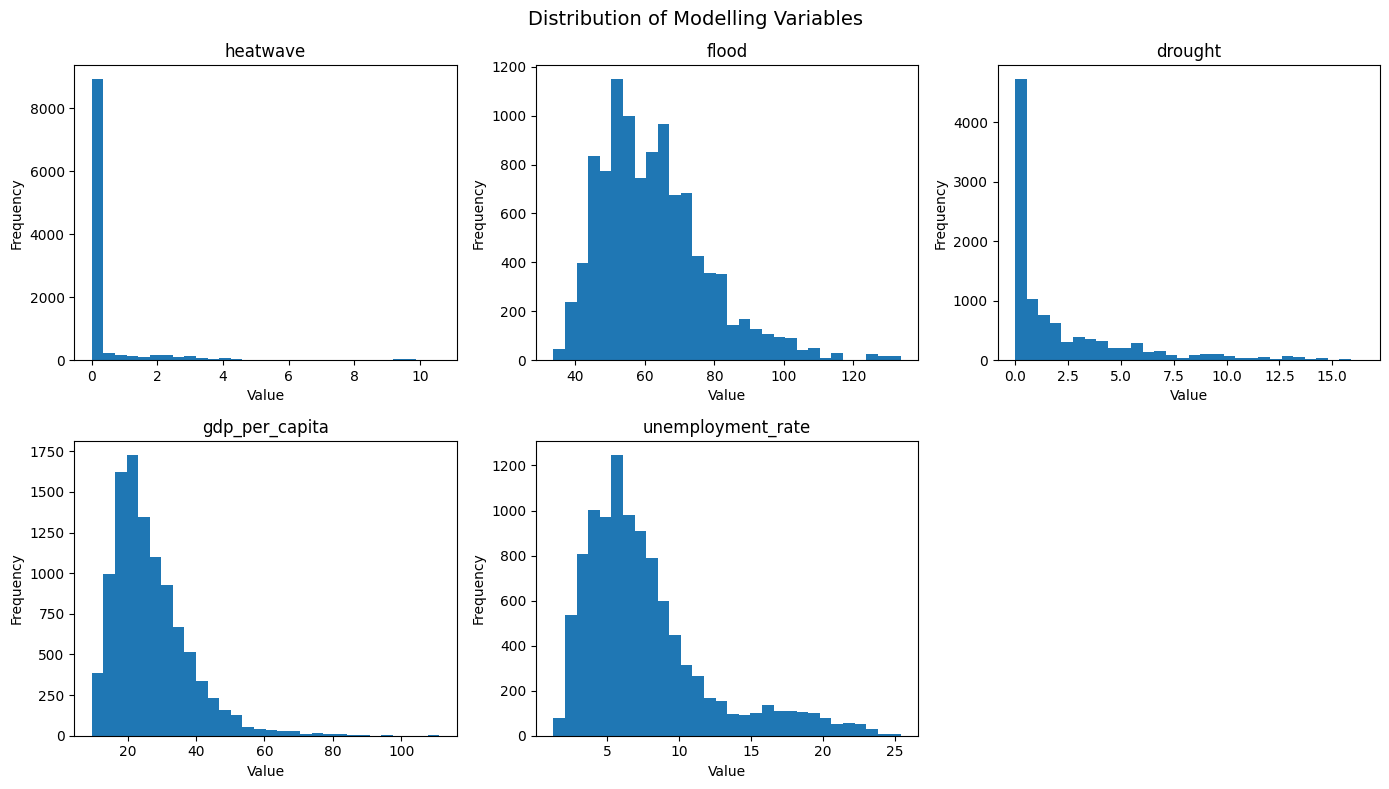

In [24]:
# ============================================================
# Histograms - Distribution of Modelling Variables
# ============================================================

numeric_cols = [
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate",
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].hist(master289[col], bins=30)
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

# Hide unused 6th panel
axes[-1].axis("off")

plt.suptitle("Distribution of Modelling Variables", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation** The histograms indicate that most variables are right-skewed rather than normally distributed. Heatwave and drought exhibit a high concentration of low values with a few extreme events, whereas GDP per capita and unemployment rate display broader socioeconomic variation across German districts.

#### Boxplots (Outlier Inspection)

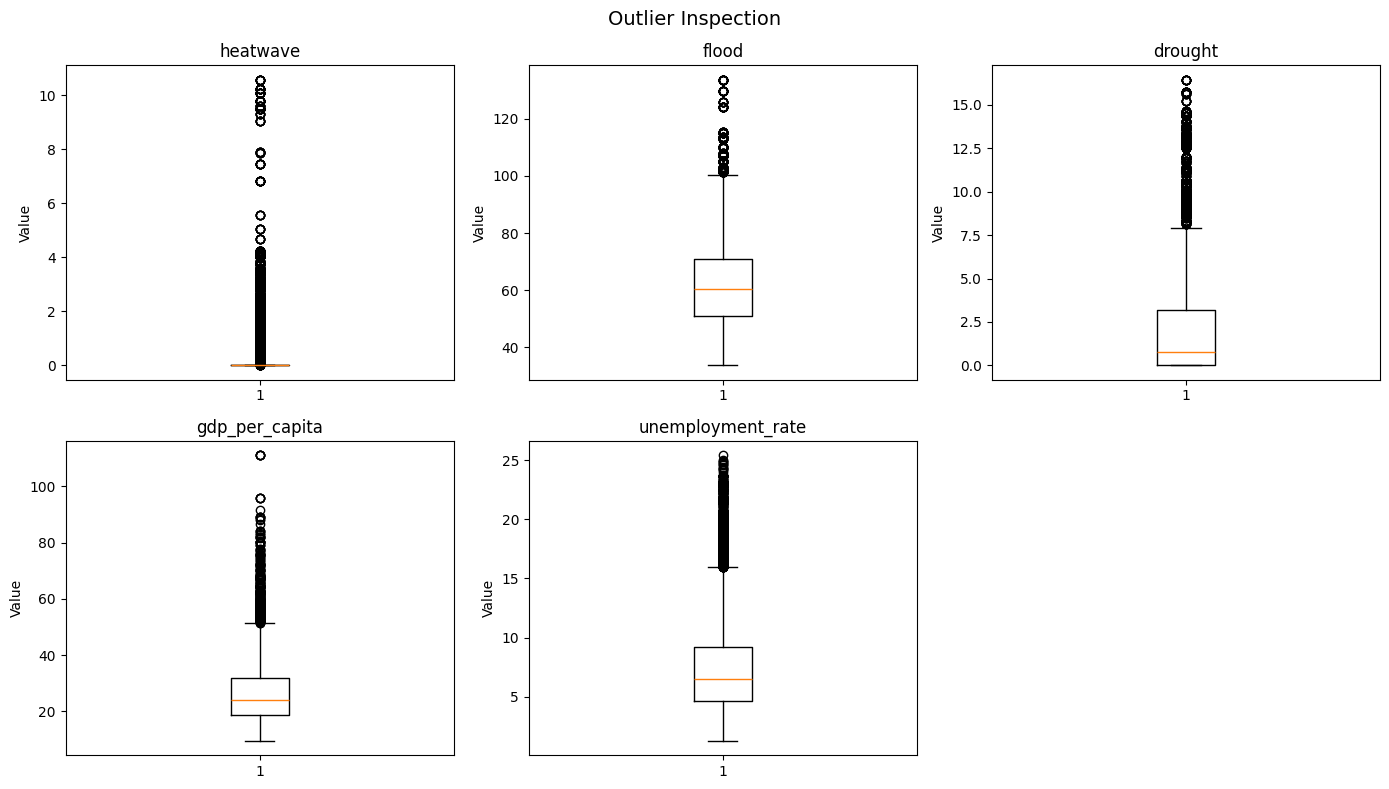

In [25]:
# ============================================================
# Boxplots - Outlier Inspection
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].boxplot(master289[col].dropna(), vert=True)
    axes[i].set_title(col)
    axes[i].set_ylabel("Value")

axes[-1].axis("off")

plt.suptitle("Outlier Inspection", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation** Boxplots reveal the presence of several outliers, particularly for heatwave, drought, flood, and GDP per capita. These observations represent genuine regional variability rather than data errors and were therefore retained for modelling.

#### Correlation Matrix

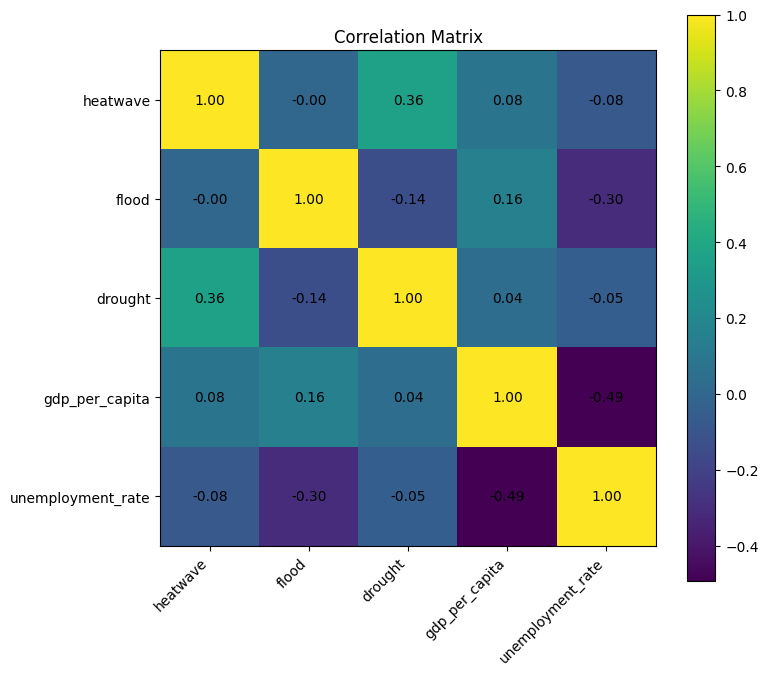

In [29]:
# ============================================================
# Correlation Matrix
# ============================================================

corr = master289[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(corr.values)

# Axis labels
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))

ax.set_xticklabels(numeric_cols, rotation=45, ha="right")
ax.set_yticklabels(numeric_cols)

# Write correlation values
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        ax.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=10,
            color="black",
        )

plt.colorbar(im)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

**Interpretation** Pairwise correlations are generally weak to moderate, indicating limited multicollinearity among predictors. The strongest association is the expected negative relationship between GDP per capita and unemployment rate (r ≈ -0.49), while heatwave and drought exhibit a moderate positive correlation (r ≈ 0.36).

#### Pairwise Relationships (Scatter Matrix)

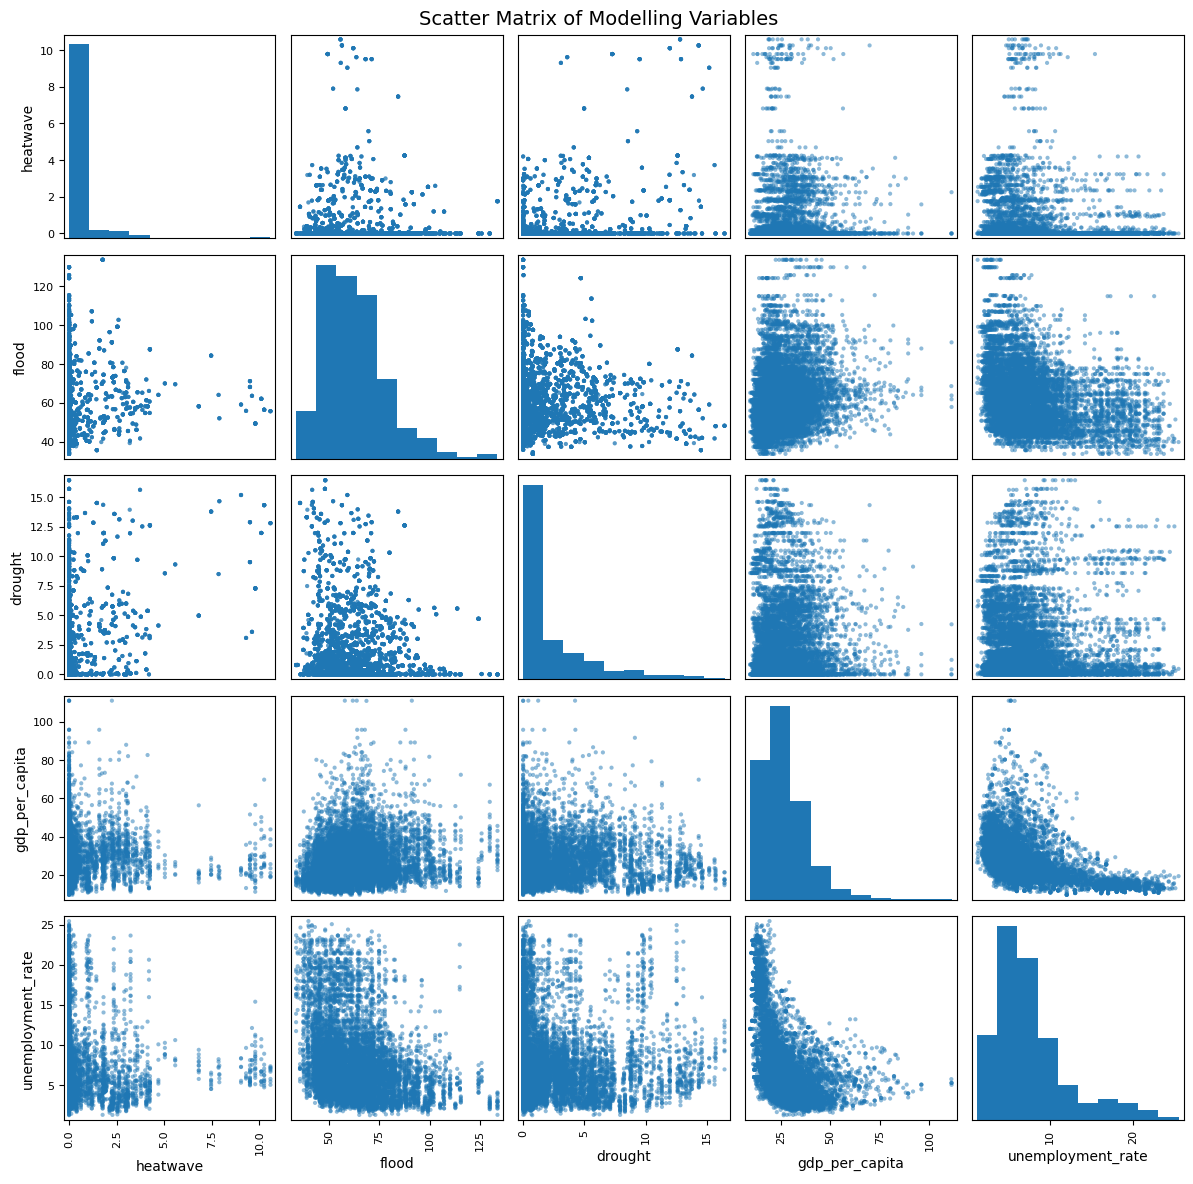

In [32]:
# ============================================================
# Pairwise Relationships (Scatter Matrix)
# ============================================================

from pandas.plotting import scatter_matrix

numeric_cols = [
    "heatwave",
    "flood",
    "drought",
    "gdp_per_capita",
    "unemployment_rate"
]

scatter_matrix(
    master289[numeric_cols],
    figsize=(12, 12),
    diagonal="hist",
    alpha=0.5,
    grid=True
)

plt.suptitle("Scatter Matrix of Modelling Variables", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation** The scatter matrix confirms the correlation analysis by visualizing pairwise relationships among all modelling variables. Most feature pairs show weak nonlinear or dispersed relationships, while GDP per capita and unemployment rate demonstrate the clearest inverse association.

#### Time Trends

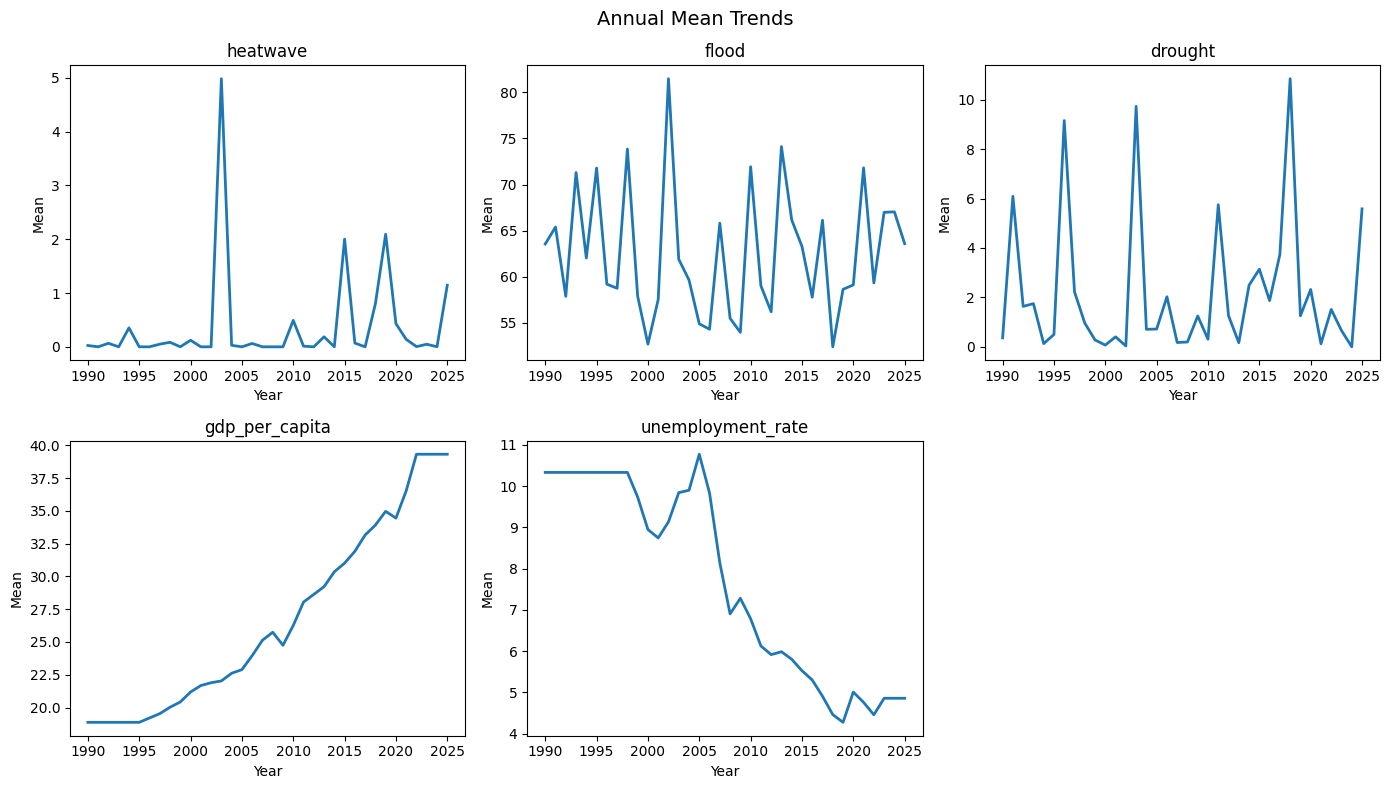

In [30]:
# ============================================================
# Mean Annual Trends
# ============================================================

yearly = master289.groupby("year")[numeric_cols].mean()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    axes[i].plot(yearly.index, yearly[col], linewidth=2)
    axes[i].set_title(col)
    axes[i].set_xlabel("Year")
    axes[i].set_ylabel("Mean")

axes[-1].axis("off")

plt.suptitle("Annual Mean Trends", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretation** Annual averages indicate a gradual increase in GDP per capita and a long-term decline in unemployment across the study period. Climate indicators exhibit substantial year-to-year variability, reflecting the episodic nature of extreme weather events rather than monotonic trends.

#### Summary Statistics

In [ ]:
# ============================================================
# Exploratory Data Visualization
# ============================================================

summary = (
    master289[numeric_cols]
    .describe()
    .T
)

summary["Skewness"] = master289[numeric_cols].skew()
summary["Kurtosis"] = master289[numeric_cols].kurtosis()

summary = summary.round(2)

display(summary)

,count,mean,std,min,25%,50%,75%,max,Skewness,Kurtosis
heatwave,10404.0,0.37,1.22,0.00,0.00,0.00,0.00,10.58,5.19,32.55
flood,10404.0,62.58,15.61,33.68,50.96,60.49,71.00,133.73,1.09,1.78
drought,10404.0,2.21,3.17,0.00,0.00,0.77,3.22,16.43,1.93,3.47
gdp_per_capita,10404.0,26.66,11.16,9.49,18.89,24.07,31.96,111.15,1.66,4.99
unemployment_rate,10404.0,7.67,4.43,1.25,4.63,6.52,9.16,25.43,1.46,1.93


**Interpretation:** The summary statistics indicate that the climate variables are strongly right-skewed, reflecting the infrequent occurrence of extreme weather events. In contrast, GDP per capita and unemployment rate exhibit substantial regional variation across German districts. The observed distributional characteristics motivate evaluation of feature transformations where appropriate, while the differing measurement scales justify feature scaling prior to neural network training.

**Implications for Feature Engineering**

The exploratory analysis indicates that the predictor variables exhibit different distributional characteristics. Heatwave and drought display substantial positive skewness, reflecting the infrequent occurrence of extreme climate events and a high concentration of zero or low values. Flood, GDP per capita, and unemployment rate are comparatively less skewed and retain meaningful variation on their original scales.

These distributional properties have important implications for neural network modelling. Highly skewed variables can cause a small number of extreme observations to dominate the learning process, potentially reducing model stability and predictive performance. Therefore, distributional transformations will be evaluated during the Feature Engineering stage.

Rather than applying transformations indiscriminately, each candidate transformation will be assessed quantitatively by comparing the distribution before and after transformation using summary statistics (particularly skewness) and graphical inspection. Transformations will only be retained where they demonstrably reduce skewness while preserving the interpretability of the underlying variable.

This evidence-based preprocessing strategy improves model robustness while maintaining transparency and reproducibility throughout the modelling workflow.

Consequently, the Feature Engineering stage will quantitatively evaluate a log(x + 1) transformation for the Heatwave variable and, if justified by measurable improvement in skewness, for Drought. Flood, GDP per capita, and unemployment rate will initially remain on their original scales unless further diagnostics demonstrate that transformation provides additional benefit.

### Feature Engineering & Feature Selection

### Target Variable Construction

### Train / Validation / Test Split

### Feature Scaling

### Build Feed-Forward Neural Network (PyTorch)

### Model Training

### Model Evaluation

### Model Evaluation & Visualization

### Explainability (SHAP)

### Save Model & Scaler

### Notebook Summary